# Hypothesis Testing

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/hypothesis_testing.md](../../notes/hypothesis_testing_and_confidence_intervals/hypothesis_testing.md).

The workflow is: state hypotheses, choose $\alpha$, compute a test statistic, find the p-value from the null distribution, decide, and interpret. This notebook works through each step for left-, right-, and two-tailed tests, a one-sample t-test, and a two-sample comparison with an effect size.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(1)

## 1. p-values for different alternatives

The same statistic gives different p-values depending on the direction of $H_a$. For a symmetric null distribution the two-tailed p-value is $2P(Z\ge|z|)$.

In [2]:
z_obs = 1.65
p_right = stats.norm.sf(z_obs)
p_left = stats.norm.cdf(-z_obs)   # statistic observed at -1.65 for the left-tailed case
p_two = 2 * stats.norm.sf(abs(z_obs))
print(f"z = +{z_obs}: right-tailed p = {p_right:.4f}")
print(f"z = -{z_obs}: left-tailed p = {p_left:.4f}")
print(f"|z| = {z_obs}: two-tailed p = {p_two:.4f}")

z = +1.65: right-tailed p = 0.0495
z = -1.65: left-tailed p = 0.0495
|z| = 1.65: two-tailed p = 0.0989


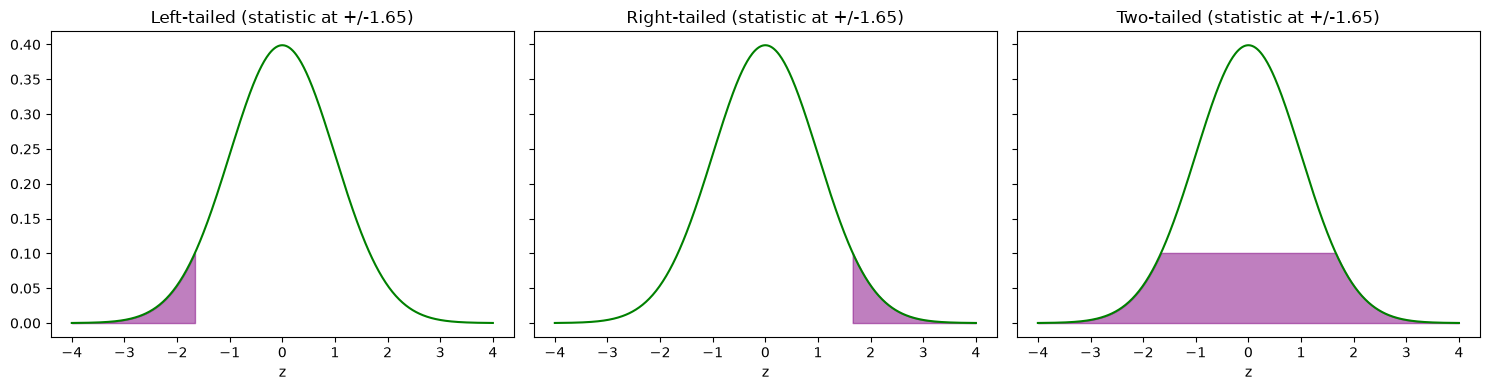

In [3]:
x = np.linspace(-4, 4, 500)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
titles = ["Left-tailed", "Right-tailed", "Two-tailed"]
for ax, title in zip(axes, titles):
    ax.plot(x, stats.norm.pdf(x), color="green")
    if title == "Left-tailed":
        mask = x <= -z_obs
    elif title == "Right-tailed":
        mask = x >= z_obs
    else:
        mask = np.abs(x) >= z_obs
    ax.fill_between(x[mask], stats.norm.pdf(x[mask]), color="purple", alpha=0.5)
    ax.set_title(title + " (statistic at +/-1.65)")
    ax.set_xlabel("z")
plt.tight_layout()
plt.show()

## 2. One-sample t-test (fertilizer example)

$H_0:\mu=2$ versus $H_a:\mu>2$ with $\bar x=2.1$, $s=0.3$, $n=25$. The note reports $t=1.667$ with critical value $1.711$.

In [4]:
xbar, s, n, mu0, alpha = 2.1, 0.3, 25, 2.0, 0.05
t_stat = (xbar - mu0) / (s / np.sqrt(n))
df = n - 1
t_crit = stats.t.ppf(1 - alpha, df)
p_val = stats.t.sf(t_stat, df)
print(f"t = {t_stat:.3f}, df = {df}, critical value = {t_crit:.3f}, p = {p_val:.4f}")
print("Reject H0" if p_val <= alpha else "Fail to reject H0")

t = 1.667, df = 24, critical value = 1.711, p = 0.0543
Fail to reject H0


The p-value is just above 0.05, so the result is borderline: not significant at 5%, but not strong evidence *for* the null either. A confidence interval would show the same ambiguity.

## 3. Two-sample t-test and effect size

We compare simulated apple weights from two farms (true means differ by 5 g) and report Cohen's $d$ alongside the p-value.

In [5]:
farm_a = rng.normal(150, 10, 50)
farm_b = rng.normal(155, 10, 50)

t_stat, p_val = stats.ttest_ind(farm_a, farm_b)  # pooled-variance t-test
sp = np.sqrt((farm_a.var(ddof=1) + farm_b.var(ddof=1)) / 2)
d = (farm_a.mean() - farm_b.mean()) / sp
print(f"means: {farm_a.mean():.2f} vs {farm_b.mean():.2f}")
print(f"t = {t_stat:.2f}, p = {p_val:.4f}, Cohen's d = {d:.2f}")

means: 149.64 vs 153.89
t = -2.47, p = 0.0151, Cohen's d = -0.49


## 4. Significance is not importance

The same tiny true effect ($d=0.05$) becomes "significant" once $n$ is large enough, because the standard error shrinks.

In [6]:
for n_big in (100, 1000, 10000, 100000):
    sample = rng.normal(0.5, 10, n_big)  # true mean 0.5, H0: mu = 0
    t_stat, p_val = stats.ttest_1samp(sample, 0.0)
    print(f"n={n_big:6d}  mean={sample.mean():.3f}  t={t_stat:6.2f}  p={p_val:.4g}  d={sample.mean() / sample.std(ddof=1):.3f}")

n=   100  mean=-0.237  t= -0.24  p=0.8125  d=-0.024
n=  1000  mean=0.026  t=  0.08  p=0.9356  d=0.003
n= 10000  mean=0.403  t=  4.04  p=5.46e-05  d=0.040
n=100000  mean=0.473  t= 14.97  p=1.24e-50  d=0.047


The estimated effect size stays tiny (|d| below 0.05 in every row) while the p-value shrinks dramatically once $n$ is large. Report both.